### IPD441 - Visión por Computador
# Clase 6: Activations 
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Introduction

Las redes neuronales pueden aprender a clasificar imágenes con mayor precisión que cualquier sistema diseñado directamente por humanos. Esto plantea una pregunta natural: ¿Qué han aprendido estas redes que les permite clasificar imágenes tan bien?

<div align="center">
    <img src="img/interpretability.png" alt="" width="70%" align="center" />
</div>

La visualización de características analiza que está "viendo" la red. En tanto, la atribución estudia qué parte de la imagen es responsable de que la red se active de una manera particular.

In [1]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from gradcam import *

In [3]:
from keras.applications.inception_v3 import InceptionV3

In [4]:
import json

In [5]:
inceptionv3_model = InceptionV3()

In [6]:
inceptionv3_model.layers[-1].activation = None

In [7]:
with open("imagenet_class_index.json", "r") as classes:
    class_idx = json.load(classes)

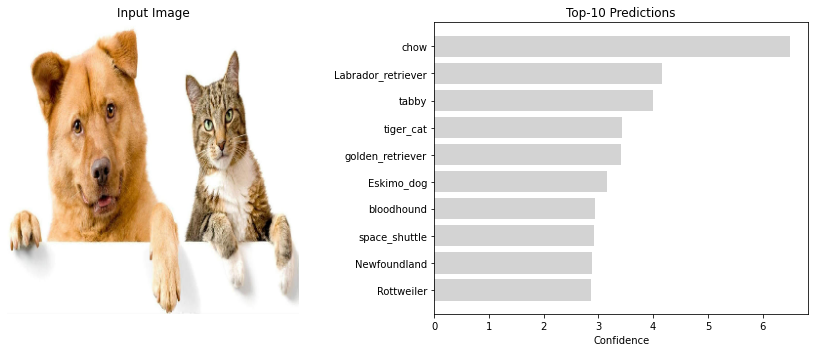

In [8]:
classify(load_img('test/dog_cat.jpeg', target_size=(299, 299)), inceptionv3_model, class_idx, n=10)

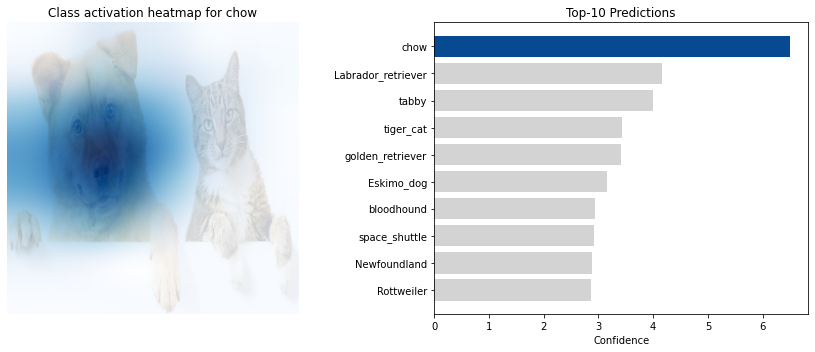

In [9]:
classify(load_img('test/dog_cat.jpeg', target_size=(299, 299)), inceptionv3_model, class_idx,
         n=10, show_grad=True, alpha=5, class_name="chow", cmap="Blues")

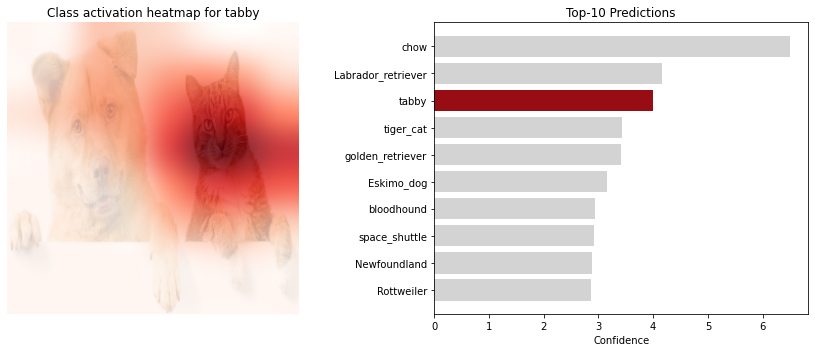

In [10]:
classify(load_img('test/dog_cat.jpeg', target_size=(299, 299)), inceptionv3_model, class_idx,
         n=10, show_grad=True, alpha=5, class_name="tabby", cmap="Reds")

In [11]:
img = np.array(Image.open("test/dogcat.jpg"), np.float32)

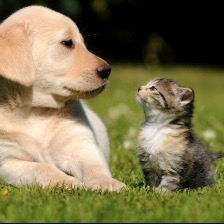

In [12]:
Image.open("test/dogcat.jpg")

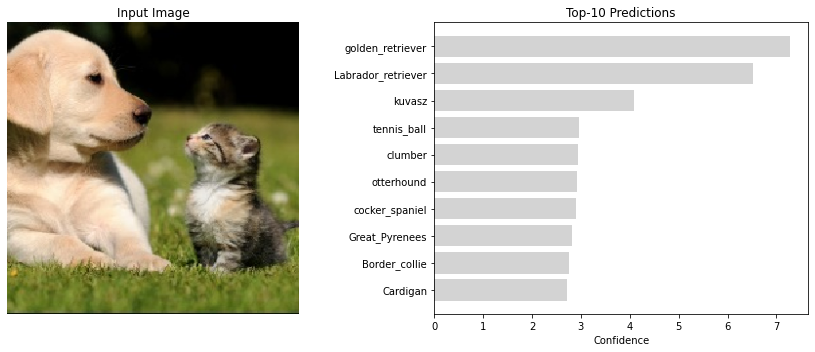

In [13]:
classify(load_img('test/dogcat.jpg', target_size=(299, 299)), inceptionv3_model, class_idx, n=10)

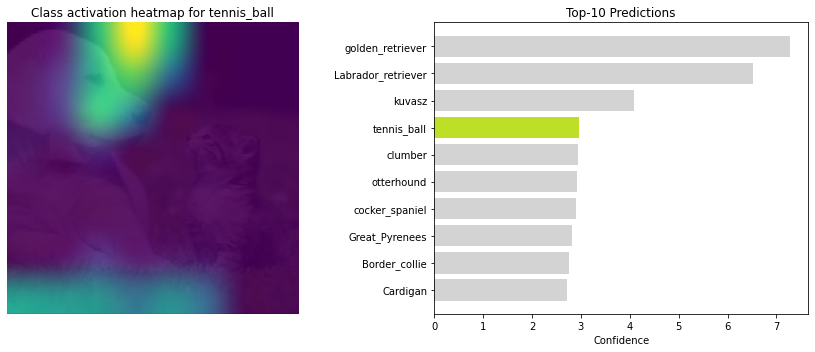

In [14]:
classify(load_img('test/dogcat.jpg', target_size=(299, 299)), inceptionv3_model, class_idx, n=10, 
         show_grad=True, alpha=10, cmap="viridis", class_name="tennis_ball")

# Looking at a Single Image

<div align="center">
    <img src="img/GoogleNet.png" alt="" width="100%" align="center" />
</div>

Para visualizar cómo InceptionV1 ve una imagen, el primer paso es introducir la imagen en la red y ejecutarla hasta la capa de interés. Luego recopilamos las activaciones, los valores numéricos de cuánto se disparó cada neurona. Si una neurona se excita por lo que se muestra, su valor de activación será positivo.

In [15]:
import torch

In [16]:
from lucent.optvis import render, param, transform, objectives
from lucent.modelzoo import inceptionv1
from lucent.misc.io import show

In [17]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
inceptionv1_model = inceptionv1(pretrained=True)
_ = inceptionv1_model.to(device).eval()

In [18]:
@objectives.wrap_objective()
def dot_compare(layer, batch=1, cossim_pow=0):
    def inner(T):
        dot = (T(layer)[batch] * T(layer)[0]).sum()
        mag = torch.sqrt(torch.sum(T(layer)[0]**2))
        cossim = dot/(1e-6 + mag)
        return -dot * cossim ** cossim_pow
    return inner

In [19]:
def feature_inversion(model, img, layers=None, n_steps=512, cossim_pow=0.0):
    list_of_images = []
    img = torch.tensor(np.transpose(img, [2, 0, 1])).to(device)
    upsample = torch.nn.Upsample(224)
    img = upsample(img)
    
    params, image_f = param.image(224)
    def stacked_param_f():
        return params, lambda: torch.stack([image_f()[0], img])
    
    transforms = [
        transform.pad(8, mode='constant', constant_value=.5),
        transform.jitter(8),
        transform.random_scale([0.9, 0.95, 1.05, 1.1] + [1]*4),
        transform.random_rotate(list(range(-5, 5)) + [0]*5),
        transform.jitter(2),
        ]
    
    for layer in layers:
        
        obj = objectives.Objective.sum([
            1.0 * dot_compare(layer, cossim_pow=cossim_pow),
            objectives.blur_input_each_step(),
        ])

        out = render.render_vis(model, 
                                obj, 
                                stacked_param_f, 
                                transforms=transforms, 
                                thresholds=(n_steps,), 
                                show_image=False, 
                                progress=False)
        list_of_images.append(out[0][0])
    show(list_of_images, labels=layers)


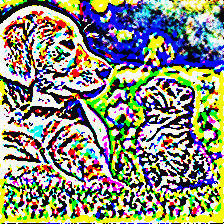
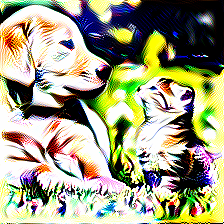
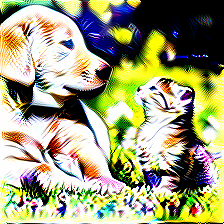
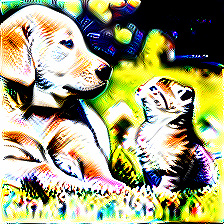
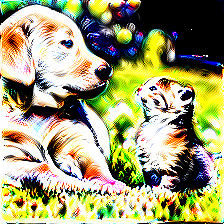
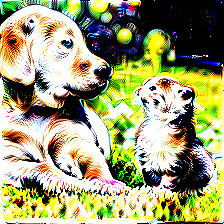

In [8]:
l = ["conv2d0", "conv2d1", "conv2d2", "mixed3a", "mixed3b", "mixed4a"]
feature_inversion(inceptionv1_model, img, layers=l)


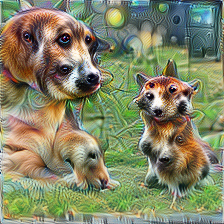
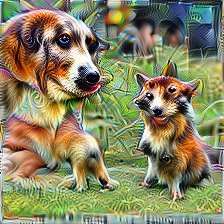
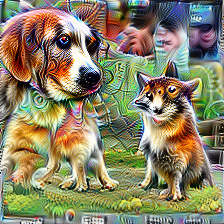
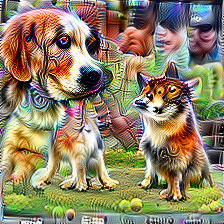
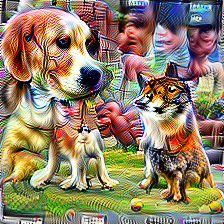
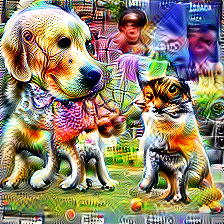

In [9]:
l = ["mixed4b", "mixed4c", "mixed4d", "mixed4e", "mixed5a", "mixed5b"]
feature_inversion(inceptionv1_model, img, layers=l)

# Making Sense of Hidden Layers

El poder de las redes neuronales reside en sus capas ocultas, donde la red descubre una nueva representación de la entrada. Podemos pensar en la representación aprendida de cada capa como un cubo tridimensional. Cada celda del cubo es una activación, o la cantidad que dispara una neurona. Los ejes $x$ e $y$ corresponden a posiciones en la imagen, y el eje $z$ es el canal (o detector) que se está ejecutando.

<div align="center">
    <img src="img/cube.png" alt="" width="80%" align="center" />
</div>


In [20]:
from helper import *

a4,1 = [0,0,0,0,199.11,0,0,164.72,147.81,209.97,0,154.00,...]



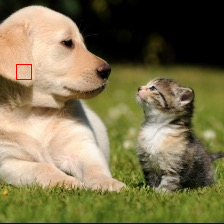
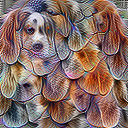
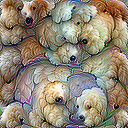
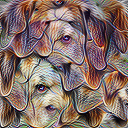

In [11]:
semantic_dictionary(img, (4,1), inceptionv1_model, layer="mixed4d")

a2,4 = [0,0,0,0,0,0,0,0,337.41,16.62,0,0,...]



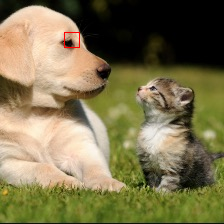
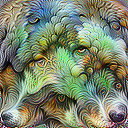
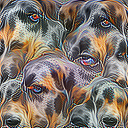
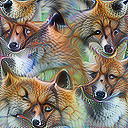

In [12]:
semantic_dictionary(img, (2,4), inceptionv1_model, layer="mixed4d")

a4,6 = [0,0,0,0,258.03,0,0,0,0,0,0,0,...]



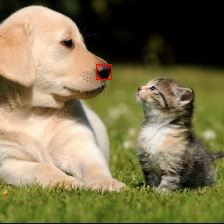
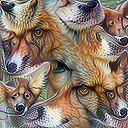
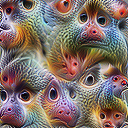
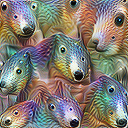

In [13]:
semantic_dictionary(img, (4,6), inceptionv1_model, layer="mixed4d")

a5,9 = [0,132.99,0,0,0,0,0,122.16,0,0,0,0,...]



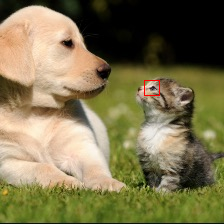
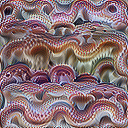
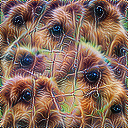
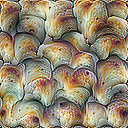

In [14]:
semantic_dictionary(img, (5,9), inceptionv1_model, layer="mixed4d")

a0,6 = [0,0,119.78,345.17,0,445.43,0,0,0,0,150.58,129.88,...]



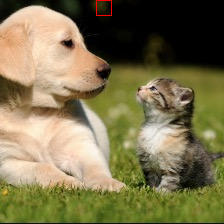
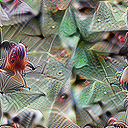
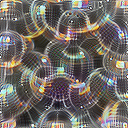
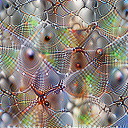

In [41]:
semantic_dictionary(img, (0,6), inceptionv1_model, layer="mixed4d")

# ¿Qué ve la red?

Aplicando esta técnica a todos los vectores de activación nos permite no solo ver lo que la red detecta en cada posición, sino también lo que la red entiende de la imagen de entrada en su conjunto.

# Activation Grids

In [15]:
grid_4a = render_activation_grid(img, inceptionv1_model, layer="mixed4a")

In [16]:
grid_4d = render_activation_grid(img, inceptionv1_model, layer="mixed4d")

In [17]:
grid_5a = render_activation_grid(img, inceptionv1_model, layer="mixed5a")

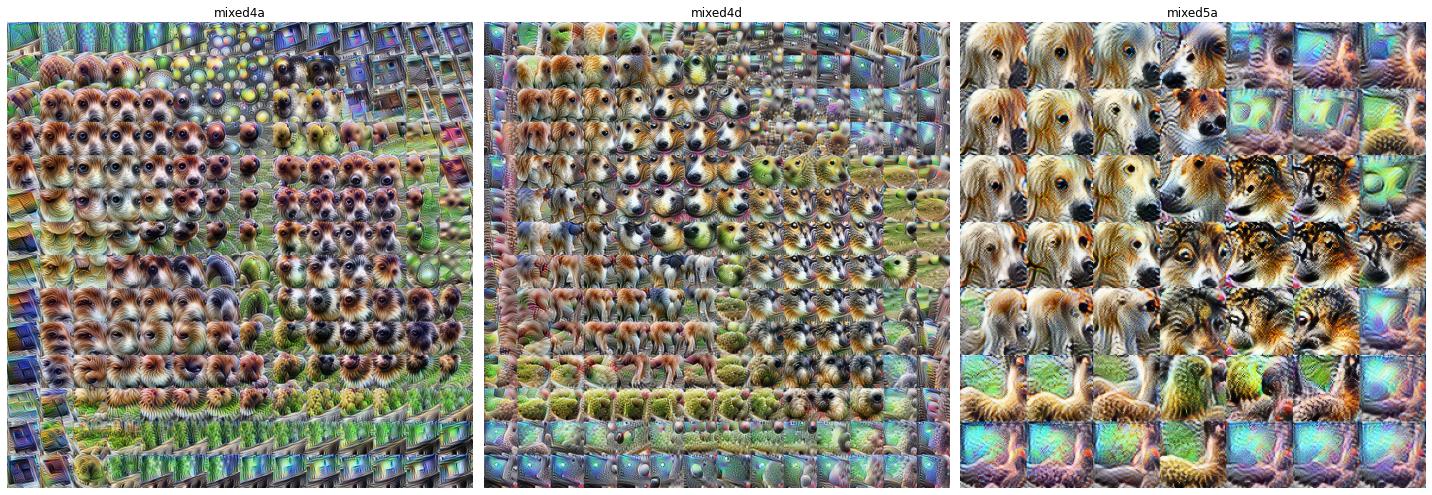

In [18]:
plot_grid_layers([grid_4a, grid_4d, grid_5a], ["mixed4a", "mixed4d", "mixed5a"])

# Aggregating Multiple Images

Las "Activation Grids" muestran cómo la red ve una sola imagen, pero ¿y si queremos ver más? ¿Qué pasa si queremos entender cómo reacciona ante millones de imágenes?

<div align="center">
    <img src="img/atlases.png" alt="" width="80%" align="center" />
</div>

<div align="center">
    <img src="img/fruits.png" alt="" width="80%" align="center" />
    <img src="img/crowd.png" alt="" width="80%" align="center" />
    <img src="img/water-beach-rocks.png" alt="" width="80%" align="center" />
</div>



# Activation Atlases


<div align="center">
    <img src="img/activations.png" alt="" width="80%" align="center" />
</div>

# Looking at Multiple Layers

<div align="center">
    <img src="img/multilayers.png" alt="" width="100%" align="center" />
</div>

Las redes convolucionales son generalmente profundas y constan de muchas capas que progresivamente construyen abstracciones más poderosas. Para obtener una visión holística, debemos observar cómo se desarrollan las abstracciones del modelo en varias capas.

## Repollo en `mixed3b`, `mixed4c` y `mixed5b`

<div align="center">
    <img src="img/repollo.png" alt="" width="100%" align="center" />
</div>

## Arena en `mixed3b`, `mixed4c` y `mixed5b`

<div align="center">
    <img src="img/sandbar.png" alt="" width="100%" align="center" />
</div>

## Mamíferos en `mixed4a`?

<div align="center">
    <img src="img/progress-mixed4a.jpg" alt="" width="70%" align="center" />
</div>

## Animales, personas, frutas en `mixed4b`?

<div align="center">
    <img src="img/progress-mixed4b.jpg" alt="" width="70%" align="center" />
</div>

# Focusing on a Single Classification

Resaltar las activaciones específicas de clase in situ de un atlas completo es útil para ver cómo esa clase se relaciona con el espacio completo de lo que una red "puede ver".

<div align="center">
    <img src="img/locomotive-baseball.png" alt="" width="70%" align="center" />
</div>

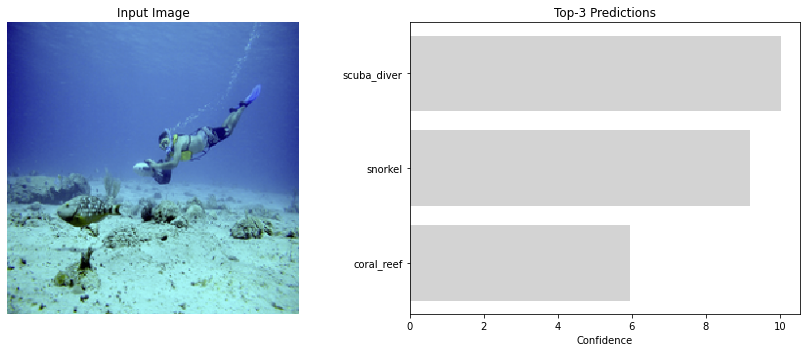

In [15]:
classify(load_img('test/snorkel.png', target_size=(299, 299)), inceptionv3_model, class_idx)

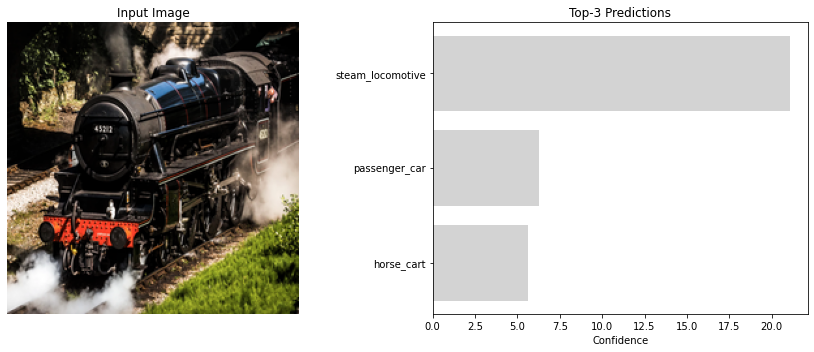

In [16]:
classify(load_img('test/train.png'), inceptionv3_model, class_idx)

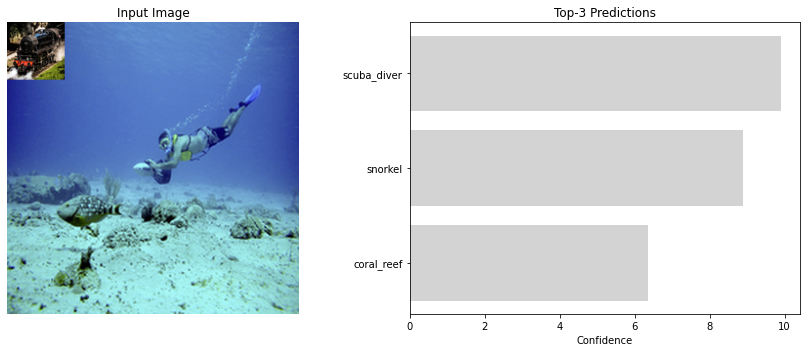

In [17]:
comp = composite_img("test/snorkel.png", "test/train.png", patch_width_ratio=0.2, patch_position=(0.0, 0.0))
classify(comp, inceptionv3_model, class_idx)

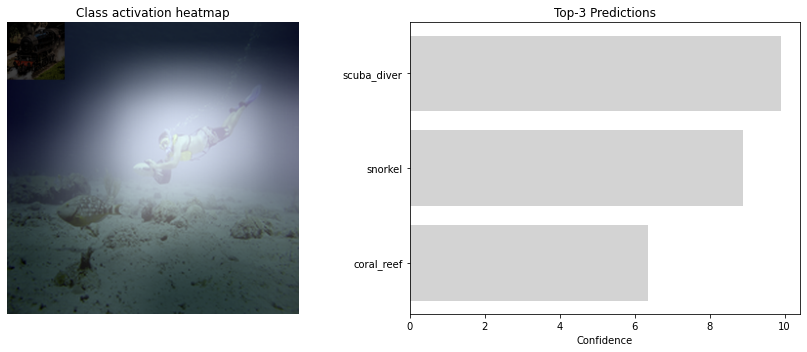

In [18]:
comp = composite_img("test/snorkel.png", "test/train.png", patch_width_ratio=0.2, patch_position=(0.0, 0.0))
classify(comp, inceptionv3_model, class_idx, show_grad=True, alpha=3)

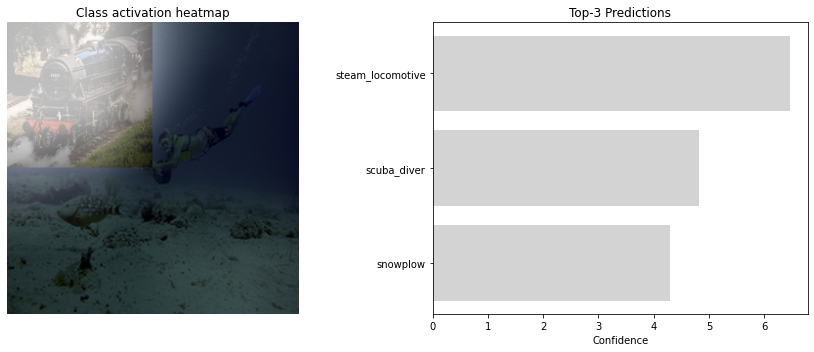

In [19]:
comp = composite_img("test/snorkel.png", "test/train.png", patch_width_ratio=0.5, patch_position=(0.0, 0.0))
classify(comp, inceptionv3_model, class_idx, show_grad=True, alpha=3)

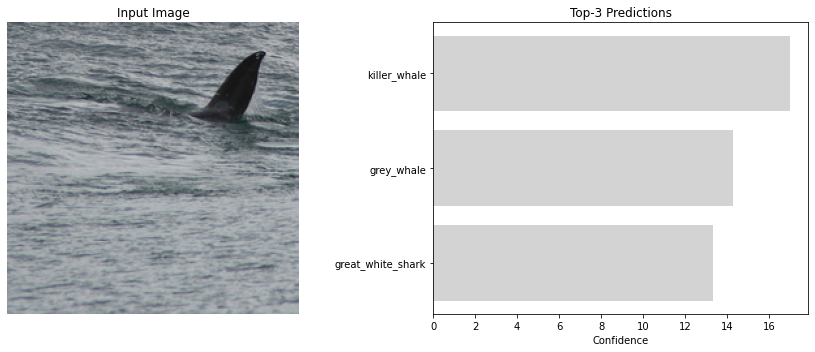

In [20]:
classify(load_img('test/whale.png'), inceptionv3_model, class_idx)

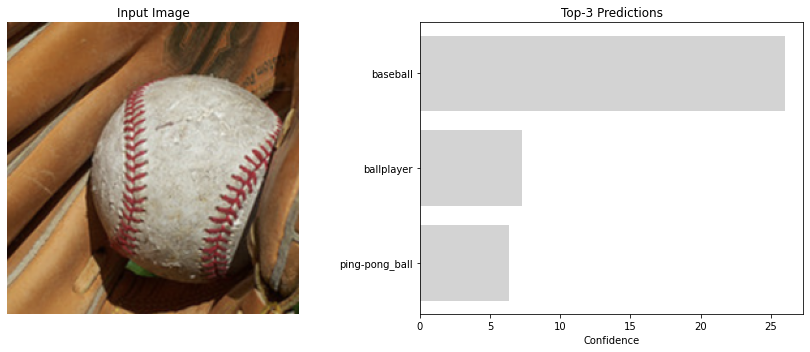

In [21]:
classify(load_img('test/baseball.png'), inceptionv3_model, class_idx)

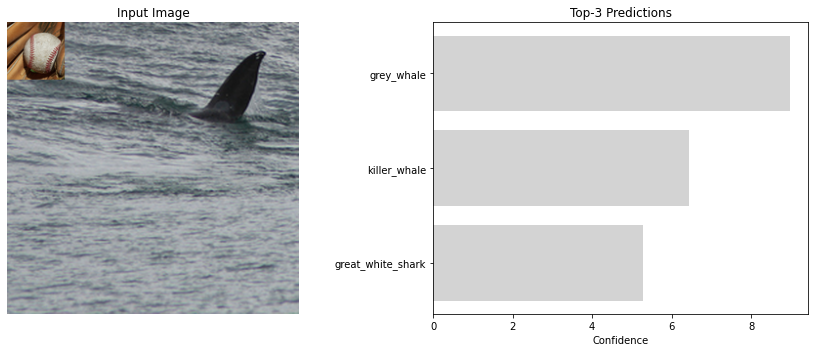

In [22]:
comp = composite_img("test/whale.png", "test/baseball.png", patch_width_ratio=0.2, patch_position=(0.0, 0.0))
classify(comp, inceptionv3_model, class_idx)

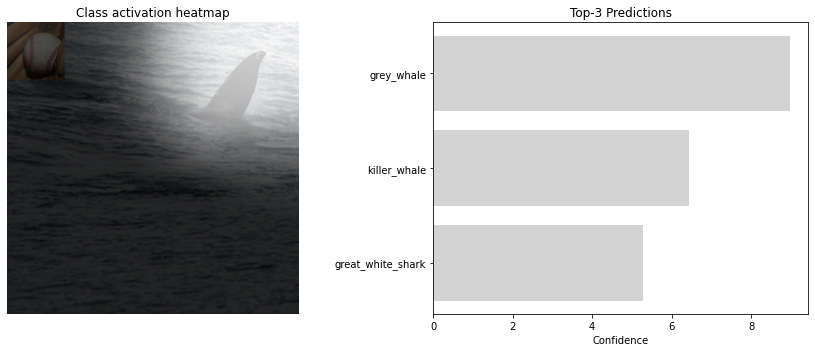

In [23]:
comp = composite_img("test/whale.png", "test/baseball.png", patch_width_ratio=0.2, patch_position=(0.0, 0.0))
classify(comp, inceptionv3_model, class_idx, show_grad=True, alpha=3)

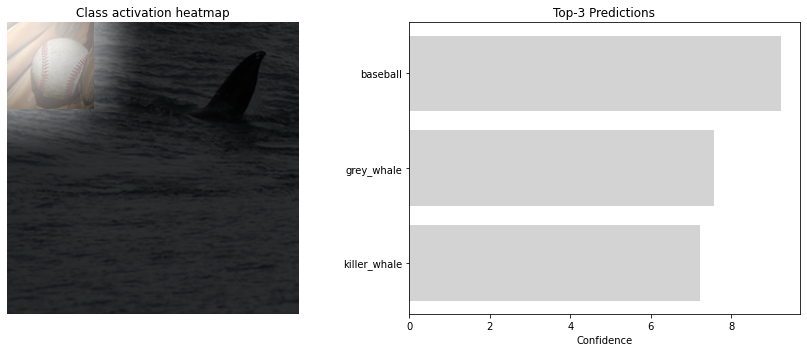

In [24]:
comp = composite_img("test/whale.png", "test/baseball.png", patch_width_ratio=0.3, patch_position=(0.0, 0.0))
classify(comp, inceptionv3_model, class_idx, show_grad=True, alpha=3)

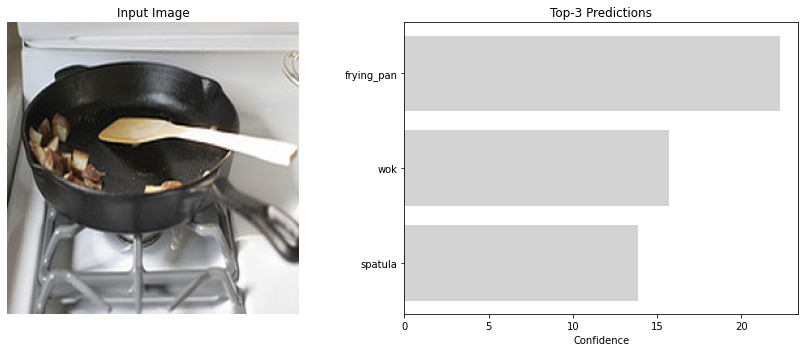

In [25]:
classify(load_img('test/sarten.png'), inceptionv3_model, class_idx)

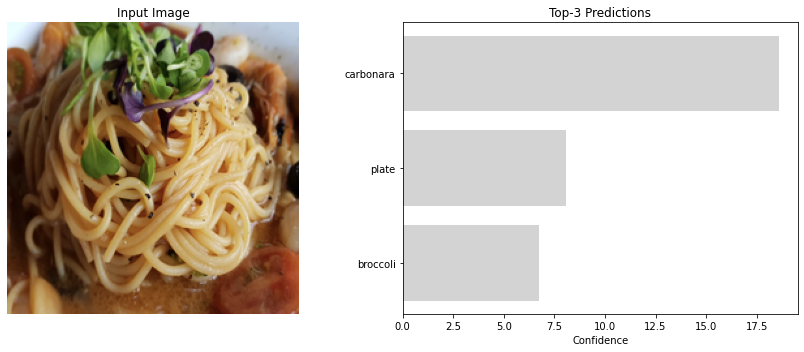

In [26]:
classify(load_img('test/pasta.png'), inceptionv3_model, class_idx)

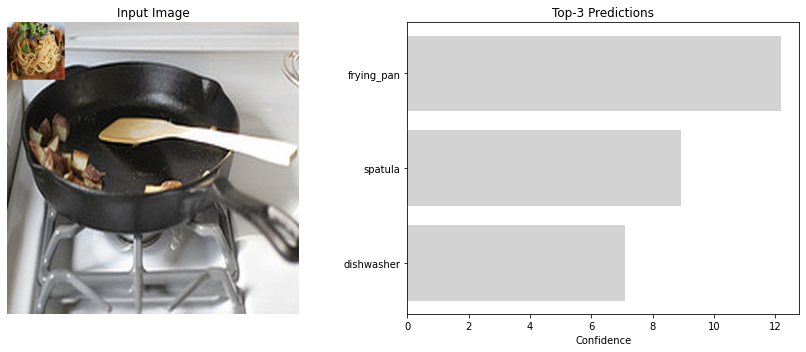

In [27]:
comp = composite_img("test/sarten.png", "test/pasta.png", patch_width_ratio=0.2, patch_position=(0.0, 0.0))
classify(comp, inceptionv3_model, class_idx)

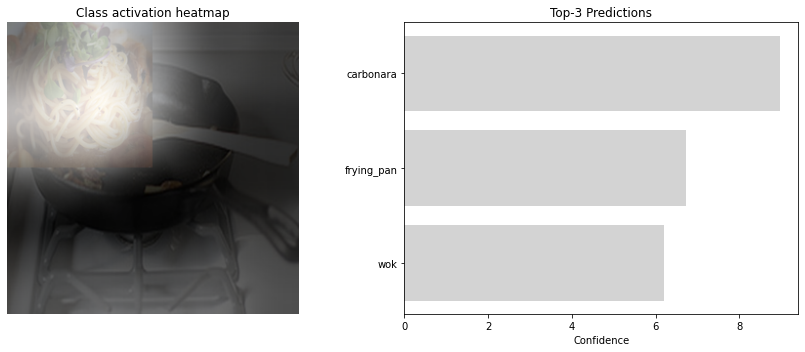

In [28]:
comp = composite_img("test/sarten.png", "test/pasta.png", size=(299,299), 
                     patch_width_ratio=0.5, patch_position=(0.0, 0.0))
classify(comp, inceptionv3_model, class_idx, show_grad=True, alpha=5)